# STEP 1 : สร้าง Dataset จาก COCO 2017
**ไฟล์คู่กัน:** `01_build_dataset_from_coco.py` (notebook นี้คือฉบับอธิบายทีละขั้น)

**เป้าหมาย:** ได้ภาพ 4 คลาส (airplane, boat, car, motorcycle) คลาสละ 150 ภาพ พร้อม label ทั้ง **Rectangle** และ **Polygon** ในรูปแบบไฟล์ JSON ของ **AnyLabeling**

```
COCO annotation (JSON ใหญ่ 450MB)
      │  คัดภาพที่แยกง่าย
      ▼
datasets/raw_images/<class>/             ภาพเปล่า (ไว้วาด label เอง)
datasets/anylabeling_rectangle/<class>/  ภาพ + JSON แบบ rectangle
datasets/anylabeling_polygon/<class>/    ภาพ + JSON แบบ polygon
```

In [1]:
# ===== ตั้งค่าเริ่มต้น (ทุก notebook ใช้เหมือนกัน) =====
import os, sys, json
from pathlib import Path
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"      # กัน error OMP บน Windows

# notebook อยู่ใน final_dip/scripts/  ->  ย้ายไปทำงานที่ final_dip/ (path ทุกอย่างอ้างอิงจากที่นี่)
ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
os.chdir(ROOT)
CLASSES = ["airplane", "boat", "car", "motorcycle"]
print("ทำงานที่:", ROOT)
from collections import Counter, defaultdict
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt

ทำงานที่: C:\code\ImageProcessing\yolo\yolo_lab\final_dip


## 1.1 ดาวน์โหลดไฟล์ annotation ของ COCO
COCO คือ dataset สาธารณะที่มีคนวาด label ไว้แล้วกว่า 8 แสนวัตถุ ทั้งแบบกรอบ (bbox) และ polygon (segmentation)
ไฟล์ zip ใหญ่ประมาณ 250 MB ดาวน์โหลดครั้งเดียว ถ้ามีไฟล์แล้ว cell นี้จะข้ามเอง

In [2]:
ANN = Path("coco/annotations/instances_train2017.json")

if not ANN.exists():
    import requests, zipfile, io
    url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
    print("downloading", url, "...")
    data = requests.get(url, timeout=600).content
    with zipfile.ZipFile(io.BytesIO(data)) as z:
        z.extract("annotations/instances_train2017.json", "coco")

print(ANN, f"{ANN.stat().st_size / 1e6:.0f} MB")

coco\annotations\instances_train2017.json 470 MB


## 1.2 เปิดไฟล์ดูว่าข้างในมีอะไร

In [3]:
coco = json.loads(ANN.read_text(encoding="utf-8"))

print("keys        :", list(coco.keys()))
print("images      :", len(coco["images"]), "ภาพ")
print("annotations :", len(coco["annotations"]), "วัตถุ")
print("categories  :", len(coco["categories"]), "คลาส")

keys        : ['info', 'licenses', 'images', 'annotations', 'categories']
images      : 118287 ภาพ
annotations : 860001 วัตถุ
categories  : 80 คลาส


In [4]:
# ดูเฉพาะ 4 คลาสที่เราเลือก : id ใน COCO, จำนวนวัตถุ, จำนวนภาพที่มีคลาสนั้น
cats = {c["id"]: c["name"] for c in coco["categories"] if c["name"] in CLASSES}
n_obj = Counter(a["category_id"] for a in coco["annotations"] if a["category_id"] in cats)
n_img = {cid: len({a["image_id"] for a in coco["annotations"] if a["category_id"] == cid}) for cid in cats}
pd.DataFrame([{"coco_id": cid, "class": name, "objects": n_obj[cid], "images": n_img[cid]}
              for cid, name in cats.items()])

,coco_id,class,objects,images
0,3,car,43867,12251
1,4,motorcycle,8725,3502
2,5,airplane,5135,2986
3,9,boat,10759,3025


## 1.3 หน้าตาของ label 1 ชิ้นใน COCO
- `bbox` = `[x, y, width, height]` (หน่วย pixel, x y คือมุมซ้ายบน) → ใช้ทำ **Rectangle**
- `segmentation` = `[[x1, y1, x2, y2, ...]]` จุดรอบวัตถุ → ใช้ทำ **Polygon**
- `iscrowd = 1` = กลุ่มวัตถุที่วาดรวมเป็นก้อนเดียว (เราไม่เอา)

In [5]:
car_id = [cid for cid, n in cats.items() if n == "car"][0]
a = next(a for a in coco["annotations"] if a["category_id"] == car_id and not a["iscrowd"])
show = dict(a)
show["segmentation"] = [a["segmentation"][0][:10] + ["..."]]   # ตัดให้สั้นลงตอนแสดง
show

{'segmentation': [[255.7,
   295.07,
   256.72,
   288.29,
   259.81,
   287.46,
   265.35,
   282.53,
   288.98,
   281.92,
   '...']],
 'area': 1016.6671000000003,
 'iscrowd': 0,
 'image_id': 71345,
 'bbox': [255.7, 281.92, 50.34, 28.97],
 'category_id': 3,
 'id': 131774}

## 1.4 คัดภาพที่ "แยกง่าย"
เงื่อนไข 5 ข้อ (ดูโค้ดเดียวกันได้ในฟังก์ชัน `select_images` ของไฟล์ .py)
1. ในภาพมี **คลาสเดียว** จาก 4 คลาส (ไม่ปนกัน)
2. ไม่มี `iscrowd`
3. วัตถุไม่เกิน **6 ชิ้น** ต่อภาพ
4. ทุกวัตถุใหญ่อย่างน้อย **0.5%** ของภาพ (ไม่มีวัตถุจิ๋วที่ดูไม่ออก)
5. มีวัตถุหลักใหญ่อย่างน้อย **5%** ของภาพ

ตารางด้านล่างคือจำนวนภาพที่เหลือหลังผ่านแต่ละเงื่อนไข

In [6]:
anns_by_img = defaultdict(list)
for ann in coco["annotations"]:
    if ann["category_id"] in cats:
        anns_by_img[ann["image_id"]].append(ann)
images = {im["id"]: im for im in coco["images"]}

funnel = {name: [0] * 5 for name in CLASSES}   # funnel[class][i] = จำนวนภาพที่ผ่านเงื่อนไข 1..i+1
for img_id, anns in anns_by_img.items():
    im = images[img_id]
    names = {cats[x["category_id"]] for x in anns}
    if len(names) != 1:
        continue                                   # ภาพที่มีหลายคลาส ไม่นับ
    name = names.pop()
    ratios = [x["area"] / (im["width"] * im["height"]) for x in anns]
    checks = [True,                                 # (1) คลาสเดียว
              not any(x["iscrowd"] for x in anns),  # (2) ไม่มี iscrowd
              len(anns) <= 6,                       # (3) ไม่เกิน 6 ชิ้น
              min(ratios) >= 0.005,                 # (4) ไม่มีวัตถุจิ๋ว
              max(ratios) >= 0.05]                  # (5) มีวัตถุหลักใหญ่พอ
    for i in range(5):
        if not checks[i]:
            break                                   # ตกเงื่อนไขไหน หยุดนับตรงนั้น
        funnel[name][i] += 1

cols = ["(1) คลาสเดียว", "(2) ไม่มี crowd", "(3) <=6 ชิ้น", "(4) ไม่จิ๋ว", "(5) มีตัวหลัก"]
pd.DataFrame(funnel, index=cols).T

,(1) คลาสเดียว,(2) ไม่มี crowd,(3) <=6 ชิ้น,(4) ไม่จิ๋ว,(5) มีตัวหลัก
airplane,2546,2542,2484,2036,1556
boat,2676,2524,2244,1273,813
car,10272,10022,8648,3186,1349
motorcycle,2099,2061,1923,1643,1307


## 1.5 สุ่มเลือกคลาสละ 150 ภาพ (seed = 42 → สุ่มกี่ครั้งก็ได้ชุดเดิม)

In [7]:
# โหลดฟังก์ชันจากไฟล์ .py ของขั้นนี้มาใช้ (ชื่อไฟล์ขึ้นต้นด้วยตัวเลข เลย import ตรง ๆ ไม่ได้)
import importlib.util
def load_script(name):
    spec = importlib.util.spec_from_file_location(name, f"scripts/{name}.py")
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

step1 = load_script("01_build_dataset_from_coco")
selected = step1.select_images(coco, per_class=150, max_objects=6, seed=42)

  airplane    candidates= 1556  selected=150
  boat        candidates=  813  selected=150
  car         candidates= 1349  selected=150
  motorcycle  candidates= 1307  selected=150


In [8]:
# ตัวอย่าง 5 ภาพแรกของคลาส car : จะถูกตั้งชื่อใหม่เป็น car_001.jpg, car_002.jpg, ...
pd.DataFrame([{"file": f"car_{i:03d}.jpg", "coco_id": im["id"], "size": f'{im["width"]}x{im["height"]}',
               "objects": len(anns), "url": im["coco_url"]}
              for i, (im, anns) in enumerate(selected["car"][:5], start=1)])

,file,coco_id,size,objects,url
0,car_001.jpg,507289,500x343,1,http://images.cocodataset.org/train2017/000000...
1,car_002.jpg,394151,640x427,1,http://images.cocodataset.org/train2017/000000...
2,car_003.jpg,313280,640x427,1,http://images.cocodataset.org/train2017/000000...
3,car_004.jpg,494594,497x640,1,http://images.cocodataset.org/train2017/000000...
4,car_005.jpg,487466,427x640,1,http://images.cocodataset.org/train2017/000000...


## 1.6 ภาพที่ดาวน์โหลดมา (`datasets/raw_images/<class>/`)
ภาพถูกดาวน์โหลดไว้แล้ว แยกโฟลเดอร์ตามชื่อคลาส

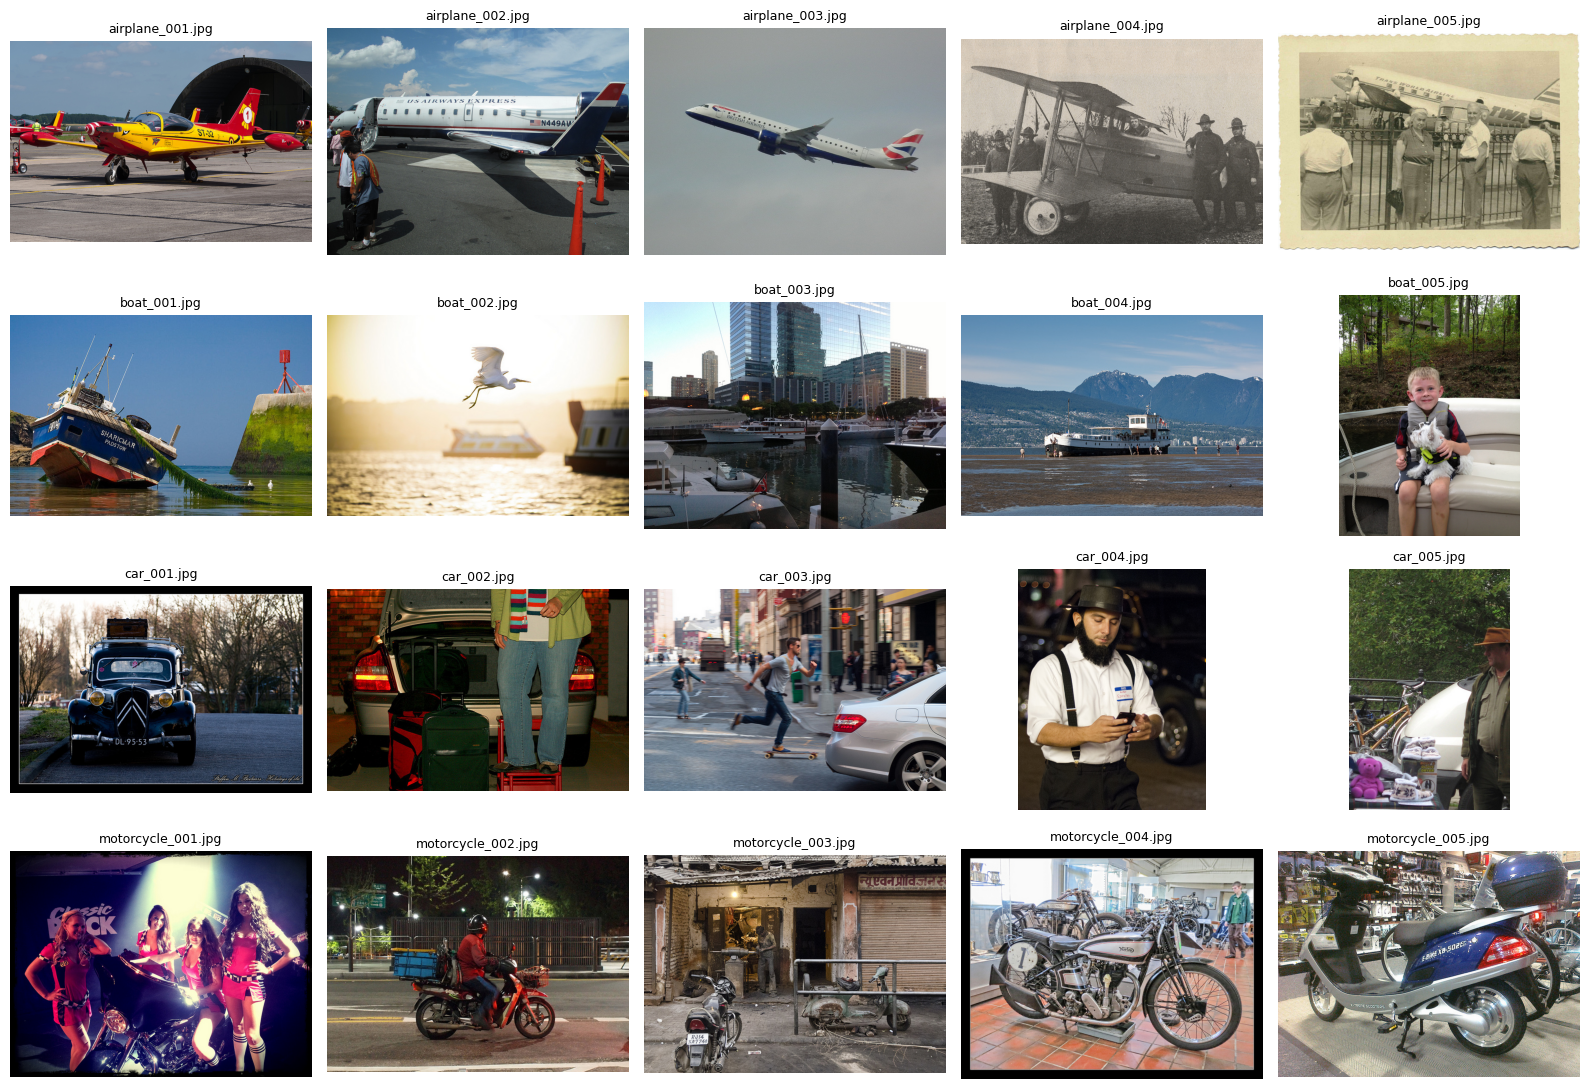

airplane    150 images
boat        150 images
car         150 images
motorcycle  150 images


In [9]:
fig, axes = plt.subplots(4, 5, figsize=(16, 11))
for r, cls in enumerate(CLASSES):
    files = sorted(Path(f"datasets/raw_images/{cls}").glob("*.jpg"))
    for c in range(5):
        axes[r, c].imshow(cv2.cvtColor(cv2.imread(str(files[c])), cv2.COLOR_BGR2RGB))
        axes[r, c].set_title(files[c].name, fontsize=9)
        axes[r, c].axis("off")
plt.tight_layout(); plt.show()
for cls in CLASSES:
    print(f"{cls:<11}", len(list(Path(f"datasets/raw_images/{cls}").glob("*.jpg"))), "images")

## 1.7 แปลง label ของ COCO เป็น JSON แบบ AnyLabeling
| | COCO | AnyLabeling |
|---|---|---|
| Rectangle | `bbox = [x, y, w, h]` | `points = [[x1, y1], [x2, y2]]`, `shape_type = "rectangle"` |
| Polygon | `segmentation = [[x1, y1, x2, y2, ...]]` | `points = [[x1, y1], [x2, y2], ...]`, `shape_type = "polygon"` |

ไฟล์ JSON ที่ได้ เปิดใน AnyLabeling ได้เลย เหมือนเราวาดเอง

In [10]:
rect_json = json.loads(Path("datasets/anylabeling_rectangle/car/car_001.json").read_text(encoding="utf-8"))
print(json.dumps(rect_json, indent=2)[:900])

{
  "version": "0.4.43",
  "flags": {},
  "shapes": [
    {
      "label": "car",
      "text": "",
      "points": [
        [
          96.7,
          85.2
        ],
        [
          306.9,
          297.0
        ]
      ],
      "group_id": null,
      "shape_type": "rectangle",
      "flags": {}
    }
  ],
  "imagePath": "car_001.jpg",
  "imageData": null,
  "imageHeight": 343,
  "imageWidth": 500
}


In [11]:
poly_json = json.loads(Path("datasets/anylabeling_polygon/car/car_001.json").read_text(encoding="utf-8"))
for s in poly_json["shapes"]:
    print(s["label"], s["shape_type"], "จำนวนจุด =", len(s["points"]), " 3 จุดแรก =", s["points"][:3])

car polygon จำนวนจุด = 51  3 จุดแรก = [[98.2, 290.9], [96.7, 215.7], [96.7, 191.9]]


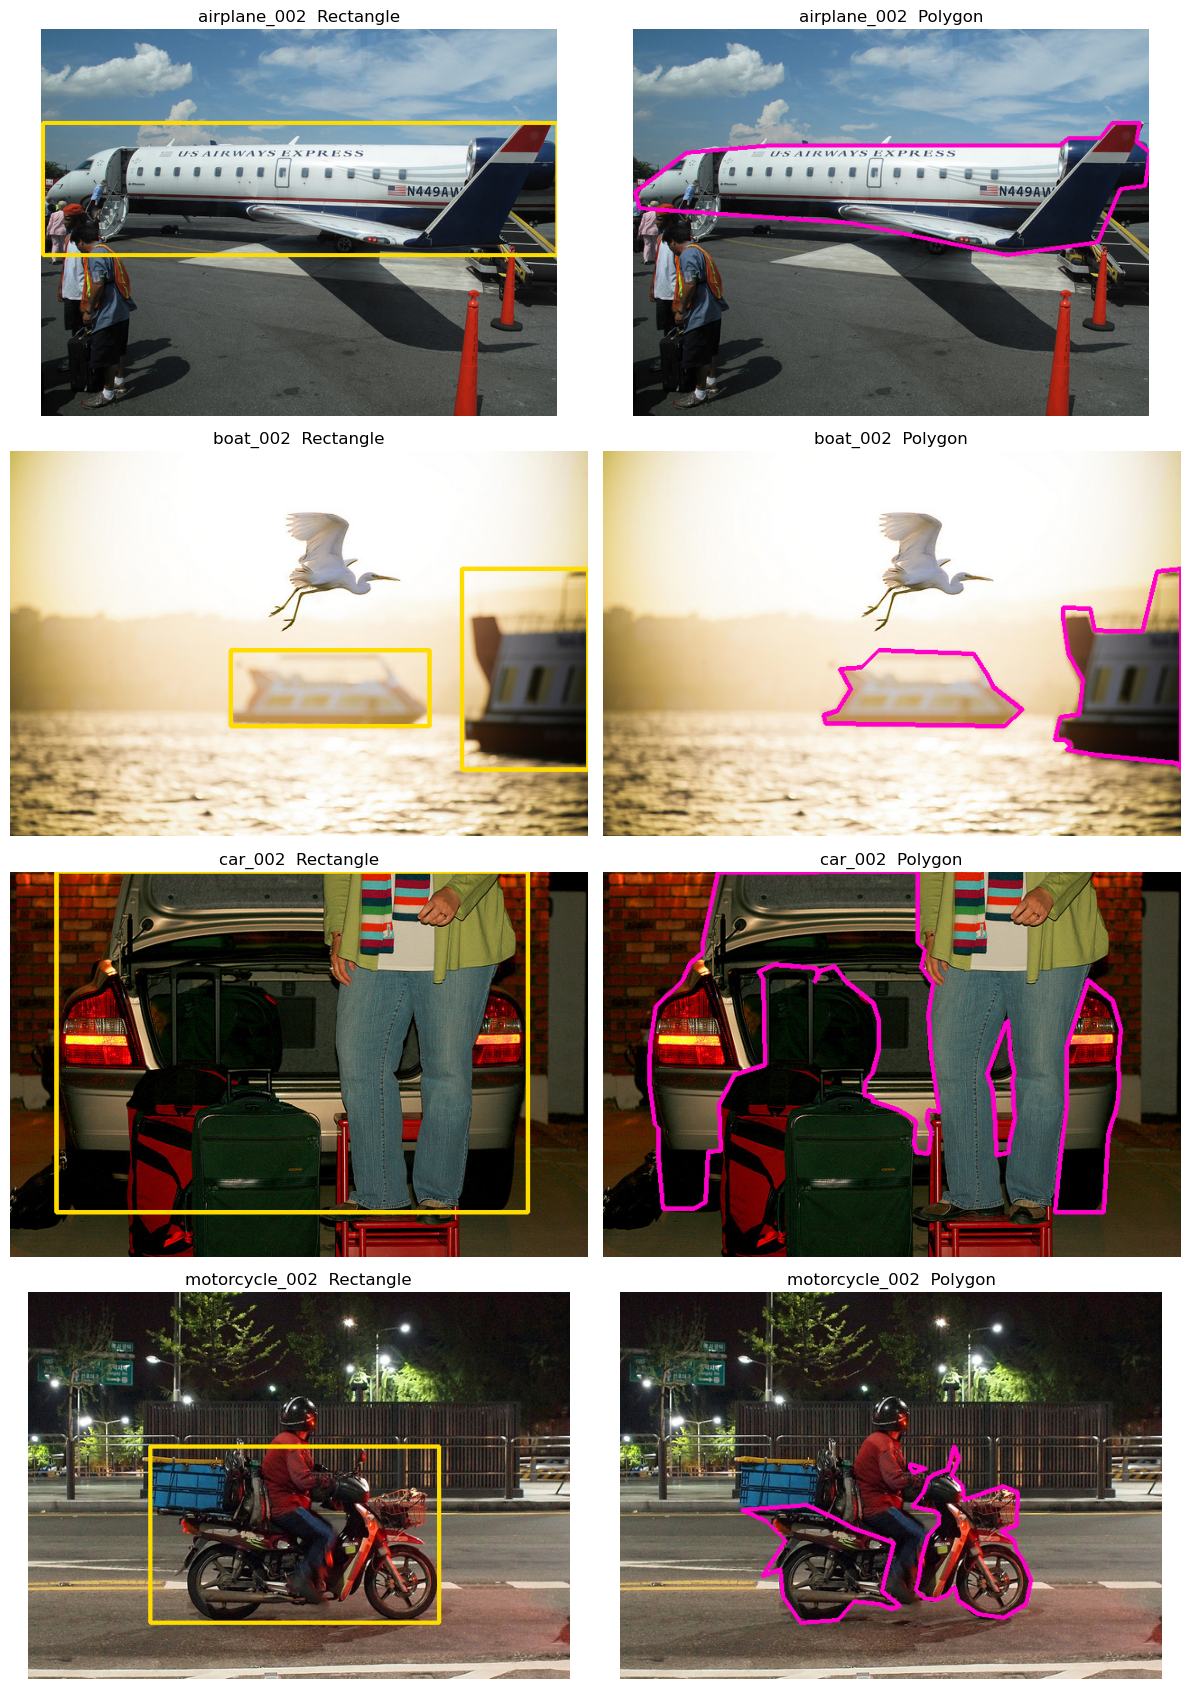

In [12]:
# วาด label จาก JSON ทับภาพ : ซ้าย = rectangle (เหลือง), ขวา = polygon (ชมพู)
def draw_json(img_path, json_path):
    im = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    data = json.loads(Path(json_path).read_text(encoding="utf-8"))
    for s in data["shapes"]:
        pts = np.array(s["points"], dtype=np.int32)
        if s["shape_type"] == "rectangle":
            cv2.rectangle(im, tuple(pts[0]), tuple(pts[1]), (255, 220, 0), 3)
        else:
            cv2.polylines(im, [pts.reshape(-1, 1, 2)], True, (255, 0, 200), 3)
    return im

fig, axes = plt.subplots(4, 2, figsize=(12, 17))
for r, cls in enumerate(CLASSES):
    f = f"{cls}_002"
    axes[r, 0].imshow(draw_json(f"datasets/raw_images/{cls}/{f}.jpg", f"datasets/anylabeling_rectangle/{cls}/{f}.json"))
    axes[r, 1].imshow(draw_json(f"datasets/raw_images/{cls}/{f}.jpg", f"datasets/anylabeling_polygon/{cls}/{f}.json"))
    axes[r, 0].set_title(f"{f}  Rectangle"); axes[r, 1].set_title(f"{f}  Polygon")
    axes[r, 0].axis("off"); axes[r, 1].axis("off")
plt.tight_layout(); plt.show()

## 1.8 เช็คเงื่อนไขโจทย์ : object ต่อ label ต้อง ≥ 100

In [13]:
rows = []
for cls in CLASSES:
    jsons = list(Path(f"datasets/anylabeling_rectangle/{cls}").glob("*.json"))
    n_obj = sum(len(json.loads(j.read_text(encoding="utf-8"))["shapes"]) for j in jsons)
    rows.append({"class": cls, "images": len(jsons), "objects": n_obj, ">= 100 ?": "ผ่าน" if n_obj >= 100 else "ไม่ผ่าน"})
pd.DataFrame(rows)

,class,images,objects,>= 100 ?
0,airplane,150,196,ผ่าน
1,boat,150,236,ผ่าน
2,car,150,238,ผ่าน
3,motorcycle,150,207,ผ่าน


## 1.9 (ถ้าต้องการ) สร้าง dataset ใหม่ทั้งหมด
ตั้ง `REBUILD = True` แล้วรัน ภาพที่มีอยู่แล้วจะไม่ถูกดาวน์โหลดซ้ำ

In [14]:
REBUILD = False
if REBUILD:
    !{sys.executable} scripts/01_build_dataset_from_coco.py --ann {ANN}
else:
    print("ข้าม (ใช้ dataset ที่มีอยู่แล้ว)")

ข้าม (ใช้ dataset ที่มีอยู่แล้ว)
